# Kaanapali Beach Segmentation — Exploratory Analysis

Explores `Kaanapali_full_segformer_v2/mask_stats.csv`: per-frame class
percentages from SegFormer-B2 over ~20.7k webcam frames
(2026-01-05 → 2026-10-08 HST, ~15-min cadence, 11,516 daytime frames).

Sections:
1. Load + QC
2. Diurnal cycle of beach vs. water
3. Long-term trends over the capture window
4. Waterline ↔ tide: NOAA Kahului Harbor water level

**NOAA data provenance** — `external_data/NOAA_water_level/CO-OPS__1615680__hr.csv`
was pulled from the CO-OPS API, station **1615680 (Kahului Harbor, Maui)**,
`product=hourly_height`, `datum=MLLW`, `time_zone=lst_ldt`, `units=english`:

    https://api.tidesandcurrents.noaa.gov/api/prod/datagetter?begin_date=20250101&end_date=20251231&station=1615680&product=hourly_height&datum=MLLW&time_zone=lst_ldt&units=english&format=csv&application=web_services

`lst_ldt` = local standard/local daylight time; Hawaii has no DST, so the
NOAA timestamps are HST and join directly to `local_dt` in mask_stats.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True

stats = pd.read_csv('Kaanapali_full_segformer_v2/mask_stats.csv')
stats['local_dt'] = pd.to_datetime(stats['local_dt'])
stats['date'] = stats['local_dt'].dt.date

day = stats[stats['is_night'] == 0].copy()
print(f'{len(stats):,} rows total | {len(day):,} day frames | '
      f"{stats['is_night'].sum():,} night-skipped")
print('capture window (HST):', day['local_dt'].min(), '->', day['local_dt'].max())
day[['pct_background','pct_beach','pct_water','roi_px']].describe().round(2)

20,703 rows total | 11,516 day frames | 9,187 night-skipped
capture window (HST): 2026-01-05 10:56:54 -> 2026-10-08 10:30:48


,pct_background,pct_beach,pct_water,roi_px
count,11516.00,11516.00,11516.00,11516.00
mean,0.35,30.19,69.47,629772.96
std,0.08,7.82,7.86,5439.30
min,0.16,6.42,48.46,623654.00
25%,0.29,24.84,62.99,628157.00
50%,0.33,29.84,69.80,628349.00
75%,0.39,36.67,74.86,628380.00
max,0.76,51.13,93.21,648528.00


## 0. QC — frozen-stream duplicates

The webcam feed occasionally froze and emitted the **identical frame** under
successive timestamps (verified byte-identical, e.g. the `20260616_034150`
run). These are not independent observations — keeping them biases any
time-aggregated stat. Dedup rule: consecutive frames (in timestamp order)
with the same file size **and** md5 → drop all but the first.

In [2]:
import hashlib, os

SRC = r'D:\Kaanapali'
day_sorted = day.sort_values('local_dt')
files = day_sorted['image'].tolist()

# only consecutive equal-size pairs can be dups — hash just those
is_dup = np.zeros(len(files), dtype=bool)
prev_md5, prev_size = None, -1
for i, f in enumerate(files):
    p = os.path.join(SRC, f)
    s = os.path.getsize(p)
    if s == prev_size:
        m = hashlib.md5(open(p, 'rb').read()).hexdigest()
        if m == prev_md5:
            is_dup[i] = True
        else:
            prev_md5 = m          # new reference inside a same-size run
    else:
        prev_size, prev_md5 = s, hashlib.md5(open(p, 'rb').read()).hexdigest()

day_sorted = day_sorted.assign(is_frozen_dup=is_dup)
print(f'{is_dup.sum():,} frozen-duplicate frames '
      f'({is_dup.mean():.1%} of day frames)')

# longest freeze runs (counting dropped copies)
runs = (day_sorted.loc[day_sorted['is_frozen_dup'], 'image']
        .groupby((~day_sorted['is_frozen_dup']).cumsum()).size())
print('longest freeze runs (dropped frames per run):',
      runs.sort_values(ascending=False).head().tolist())

day = day_sorted[~day_sorted['is_frozen_dup']].drop(columns='is_frozen_dup')
print(f'clean day frames: {len(day):,}')
day.to_csv('Kaanapali_full_segformer_v2/mask_stats_clean.csv', index=False)

233 frozen-duplicate frames (2.0% of day frames)
longest freeze runs (dropped frames per run): [36, 36, 31, 29, 26]
clean day frames: 11,283


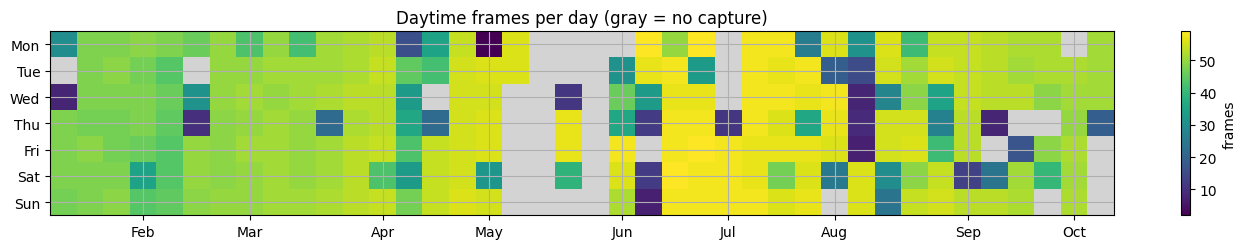

241 days with imagery | 36 missing days | median 51 frames/day
missing: ['2026-01-06', '2026-02-10', '2026-04-15', '2026-05-06', '2026-05-07', '2026-05-08', '2026-05-09', '2026-05-10', '2026-05-11', '2026-05-12', '2026-05-13', '2026-05-14', '2026-05-15', '2026-05-16', '2026-05-17'] ...


In [3]:
# frames per day — calendar heatmap so missing days are visible as blanks
per_day = day.groupby('date').size()
per_day.index = pd.to_datetime(per_day.index)

# build a weekday x week matrix covering the full window
start = per_day.index.min().normalize() - pd.Timedelta(
    days=per_day.index.min().weekday())          # Monday of first week
end = per_day.index.max().normalize()
n_weeks = (end - start).days // 7 + 1
grid = np.full((7, n_weeks), np.nan)
for d, n in per_day.items():
    grid[d.weekday(), (d - start).days // 7] = n

masked = np.ma.masked_invalid(grid)
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('lightgray')
fig, ax = plt.subplots(figsize=(14, 2.6))
im = ax.imshow(masked, aspect='auto', cmap=cmap)
ax.set_yticks(range(7), ['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
# label the first of each month at its week column
months = pd.date_range(start, end, freq='MS')
ax.set_xticks([(m - start).days // 7 for m in months],
              [m.strftime('%b') for m in months])
ax.set_title('Daytime frames per day (gray = no capture)')
plt.colorbar(im, label='frames')
plt.tight_layout(); plt.show()

missing = pd.date_range(start, end).difference(per_day.index)
print(f'{len(per_day)} days with imagery | {len(missing)} missing days | '
      f'median {int(per_day.median())} frames/day')
print('missing:', [str(d.date()) for d in missing][:15],
      '...' if len(missing) > 15 else '')

## 1. Diurnal cycle

Mean class fractions by local hour. Beach/water should be dominated by tide
phase, not time of day — but lighting (sun angle, glare) can shift the
segmentation boundary; a systematic diurnal wiggle is worth knowing about.

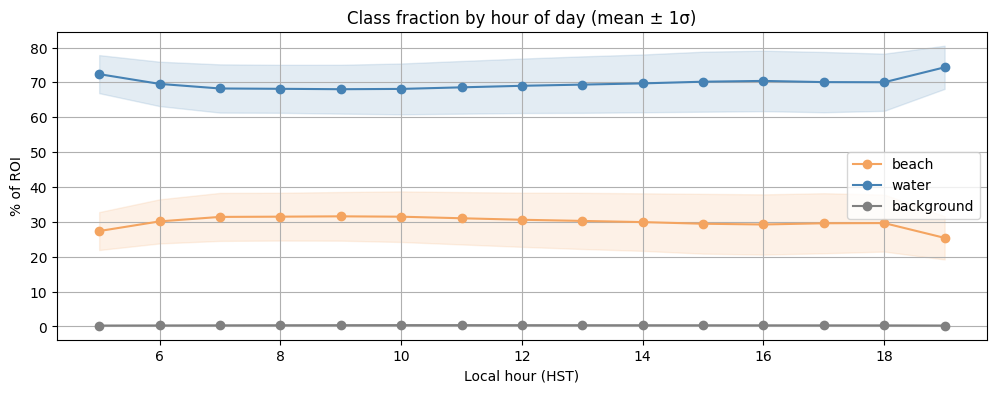

,mean,std,count
local_dt,,,
5,27.37,5.43,210
6,30.14,6.33,683
7,31.42,6.88,817
8,31.49,6.85,827
9,31.59,6.98,833
10,31.48,7.25,821
11,31.03,7.50,827
12,30.61,7.76,848
13,30.27,8.05,834


In [4]:
hourly = day.groupby(day['local_dt'].dt.hour)[
    ['pct_beach','pct_water','pct_background']].agg(['mean','std','count'])

fig, ax = plt.subplots()
for col, c in [('pct_beach','sandybrown'), ('pct_water','steelblue'), ('pct_background','gray')]:
    m = hourly[col]['mean']; s = hourly[col]['std']
    ax.plot(m.index, m, marker='o', color=c, label=col.replace('pct_',''))
    ax.fill_between(m.index, m-s, m+s, color=c, alpha=0.15)
ax.set(xlabel='Local hour (HST)', ylabel='% of ROI', title='Class fraction by hour of day (mean ± 1σ)')
ax.legend(); plt.show()
hourly['pct_beach'].round(2)

## 2. Long-term trends

Daily mean beach/water fractions across the capture window. Dips in beach %
= high-water events (spring tides, storms — e.g., the Mar 14–15 and Oct 4–5
swell/storm periods). Also watch for a discontinuity near the camera-move
epoch (late Jan 2026): the ROI polygon changes there, so level shifts around
that date may be geometric, not physical.

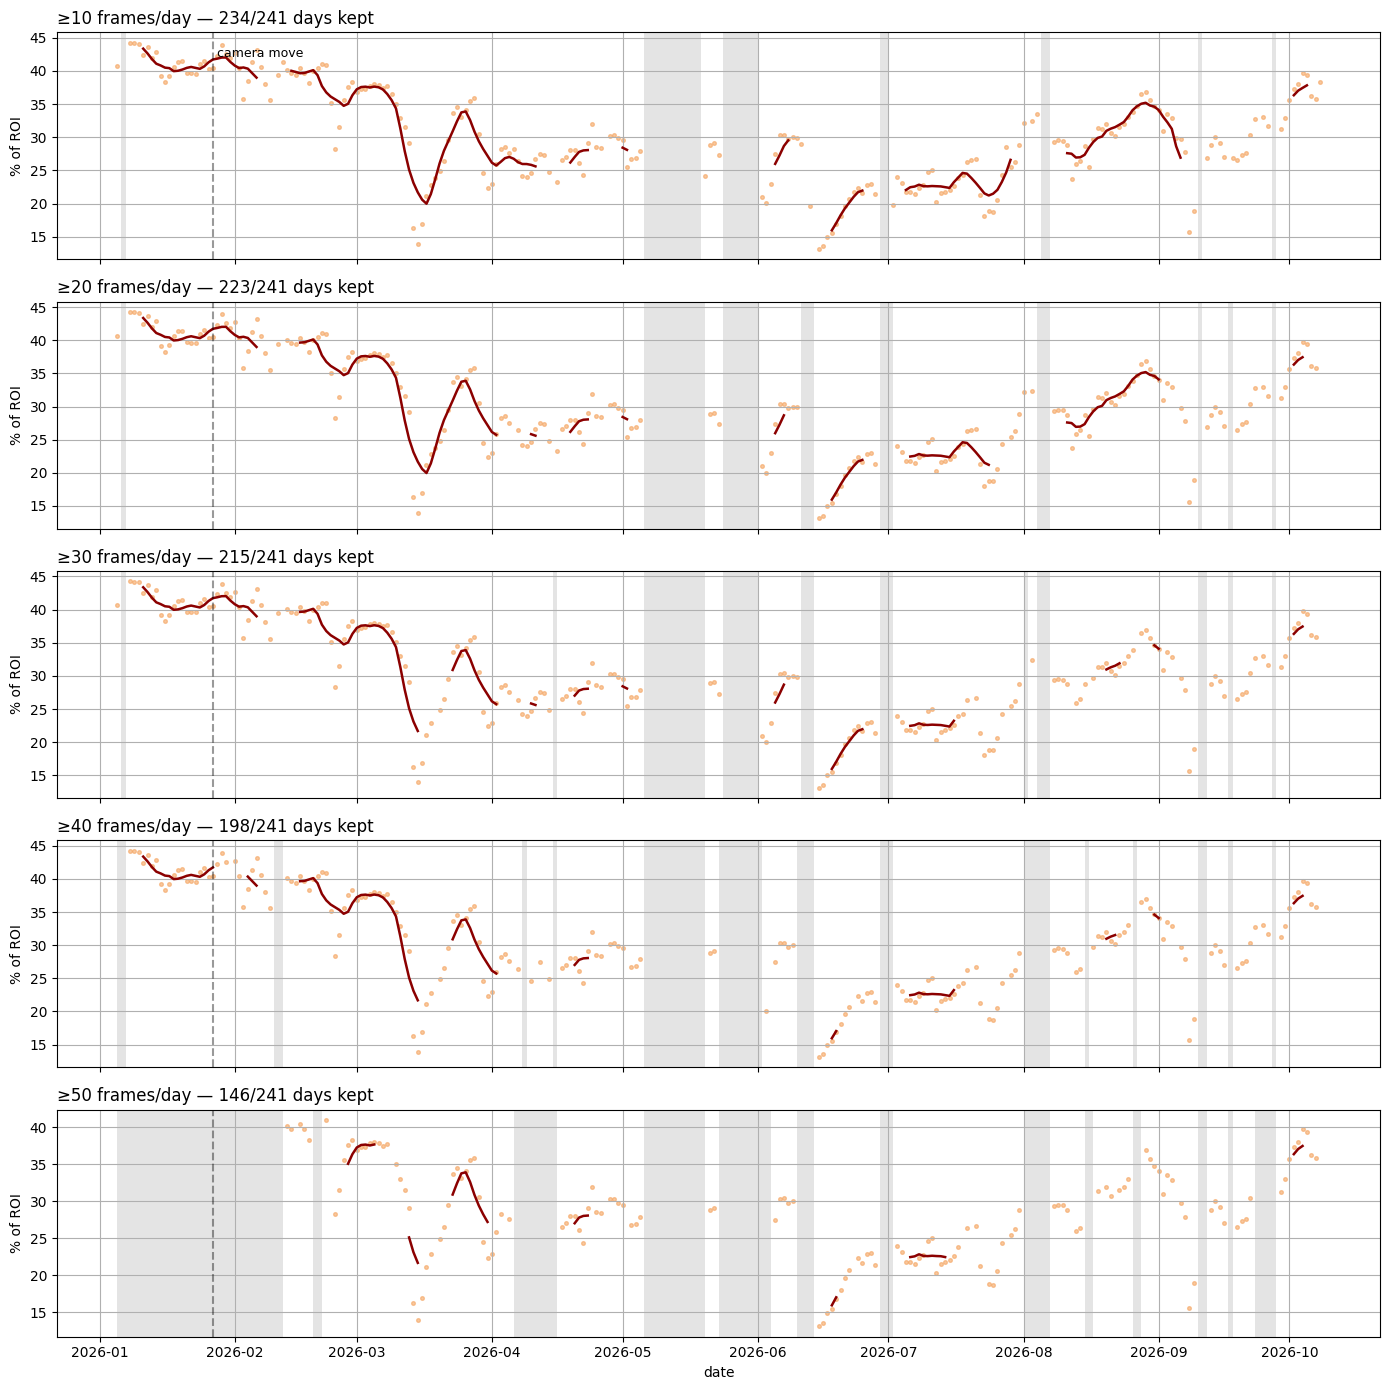

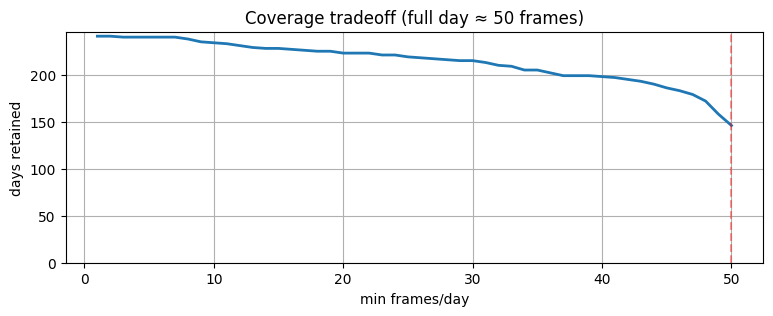

In [5]:
# Daily mean beach fraction — filtered by minimum frames/day.
# At ~4 frames/hour over ~12 daylight hours, a well-covered day has ~48 frames.
# Gray bands = days that fail the threshold (or are missing) — no line is drawn
# through them so they can't be mistaken for part of the trend.
daily_n = day.groupby('date').size()
daily_mean = day.groupby('date')[['pct_beach', 'pct_water']].mean()
daily_all = daily_mean.join(daily_n.rename('n')).sort_index()
daily_all.index = pd.to_datetime(daily_all.index)

full_idx = pd.date_range(daily_all.index.min(), daily_all.index.max(), freq='D')

def shade_gaps(ax, has_data):
    """Shade contiguous runs of days with no qualifying data."""
    gap = ~has_data
    start = None
    for d, is_gap in gap.items():
        if is_gap and start is None:
            start = d
        elif not is_gap and start is not None:
            ax.axvspan(start, d - pd.Timedelta(days=1), color='lightgray',
                       alpha=0.6, lw=0)
            start = None
    if start is not None:
        ax.axvspan(start, gap.index[-1], color='lightgray', alpha=0.6, lw=0)

fig, axes = plt.subplots(5, 1, figsize=(14, 14), sharex=True)
for ax, min_frames in zip(axes, [10, 20, 30, 40, 50]):
    d = daily_all[daily_all['n'] >= min_frames].reindex(full_idx)
    shade_gaps(ax, d['pct_beach'].notna())
    # break the rolling line wherever a gap sits inside the 7-day window
    roll = d['pct_beach'].rolling(7, center=True).mean()
    near_gap = d['pct_beach'].isna().rolling(7, center=True,
                                           min_periods=1).max().astype(bool)
    roll = roll.where(~near_gap)
    ax.scatter(d.index, d['pct_beach'], s=7, color='sandybrown', alpha=0.6)
    ax.plot(d.index, roll, color='darkred', lw=1.8)
    ax.axvline(pd.Timestamp('2026-01-27'), color='k', ls='--', alpha=0.4)
    ax.set_ylabel('% of ROI')
    kept = d['pct_beach'].notna().sum()
    ax.set_title(f'≥{min_frames} frames/day — '
                 f'{kept}/{len(daily_all)} days kept', loc='left')
axes[0].text(pd.Timestamp('2026-01-27'), axes[0].get_ylim()[1]*0.92,
             ' camera move', fontsize=9)
axes[-1].set_xlabel('date')
plt.tight_layout(); plt.show()

# day-retention curve across all thresholds
retained = [(m, (daily_all['n'] >= m).sum()) for m in range(1, 51)]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot([r[0] for r in retained], [r[1] for r in retained], lw=2)
ax.axvline(50, color='r', ls='--', alpha=0.4); ax.set_ylim(0)
ax.set(xlabel='min frames/day', ylabel='days retained',
       title='Coverage tradeoff (full day ≈ 50 frames)')
plt.show()

In [6]:
# lowest-beach days = biggest high-water events
# (restricted to days with >=10 frames so single-frame days can't skew the ranking)
daily_all[daily_all['n'] >= 10].sort_values('pct_beach').head(15).round(2)

,pct_beach,pct_water,n
date,,,
2026-06-15,13.12,86.57,50
2026-06-16,13.53,86.15,58
2026-03-15,13.94,85.79,51
2026-06-17,14.98,84.72,57
2026-06-18,15.51,84.21,58
2026-09-08,15.66,84.01,53
2026-03-14,16.30,83.46,50
2026-06-19,16.85,82.85,58
2026-03-16,16.92,82.80,51


## 3. Waterline ↔ tide (NOAA Kahului Harbor, station 1615680)

Hypothesis: `pct_water` (or equivalently waterline position) should track
predicted/measured tide height. Join hourly CO-OPS water level to the frame
stats on local hour and test the relationship.

Caveats: Kahului is on Maui's north shore ~30 km from Kaanapali — phase is
close but not identical; and `pct_water` responds to wave run-up/swell, not
just tide level, so expect scatter.

In [7]:
noaa = pd.read_csv('external_data/NOAA_water_level/CO-OPS__1615680__hr.csv',
                   skipinitialspace=True)
noaa.columns = [c.strip() for c in noaa.columns]
noaa['local_dt'] = pd.to_datetime(noaa['Date Time'], format='%m/%d/%Y %H:%M')
noaa = noaa.rename(columns={'Water Level': 'water_level_ft'})
print('NOAA range:', noaa['local_dt'].min(), '->', noaa['local_dt'].max(),
      f'| {len(noaa):,} hourly rows')

# merge: frame timestamp floored to the hour == NOAA hourly row
day['hour_bin'] = day['local_dt'].dt.floor('h')
merged = day.merge(noaa[['local_dt','water_level_ft']],
                   left_on='hour_bin', right_on='local_dt', how='inner',
                   suffixes=('','_noaa'))
print(f'{len(merged):,} frames matched to tide observations '
      f'({len(merged)/len(day):.0%} of day frames)')

NOAA range: 2026-01-01 00:00:00 -> 2026-08-31 13:00:00 | 5,822 hourly rows
9,740 frames matched to tide observations (86% of day frames)


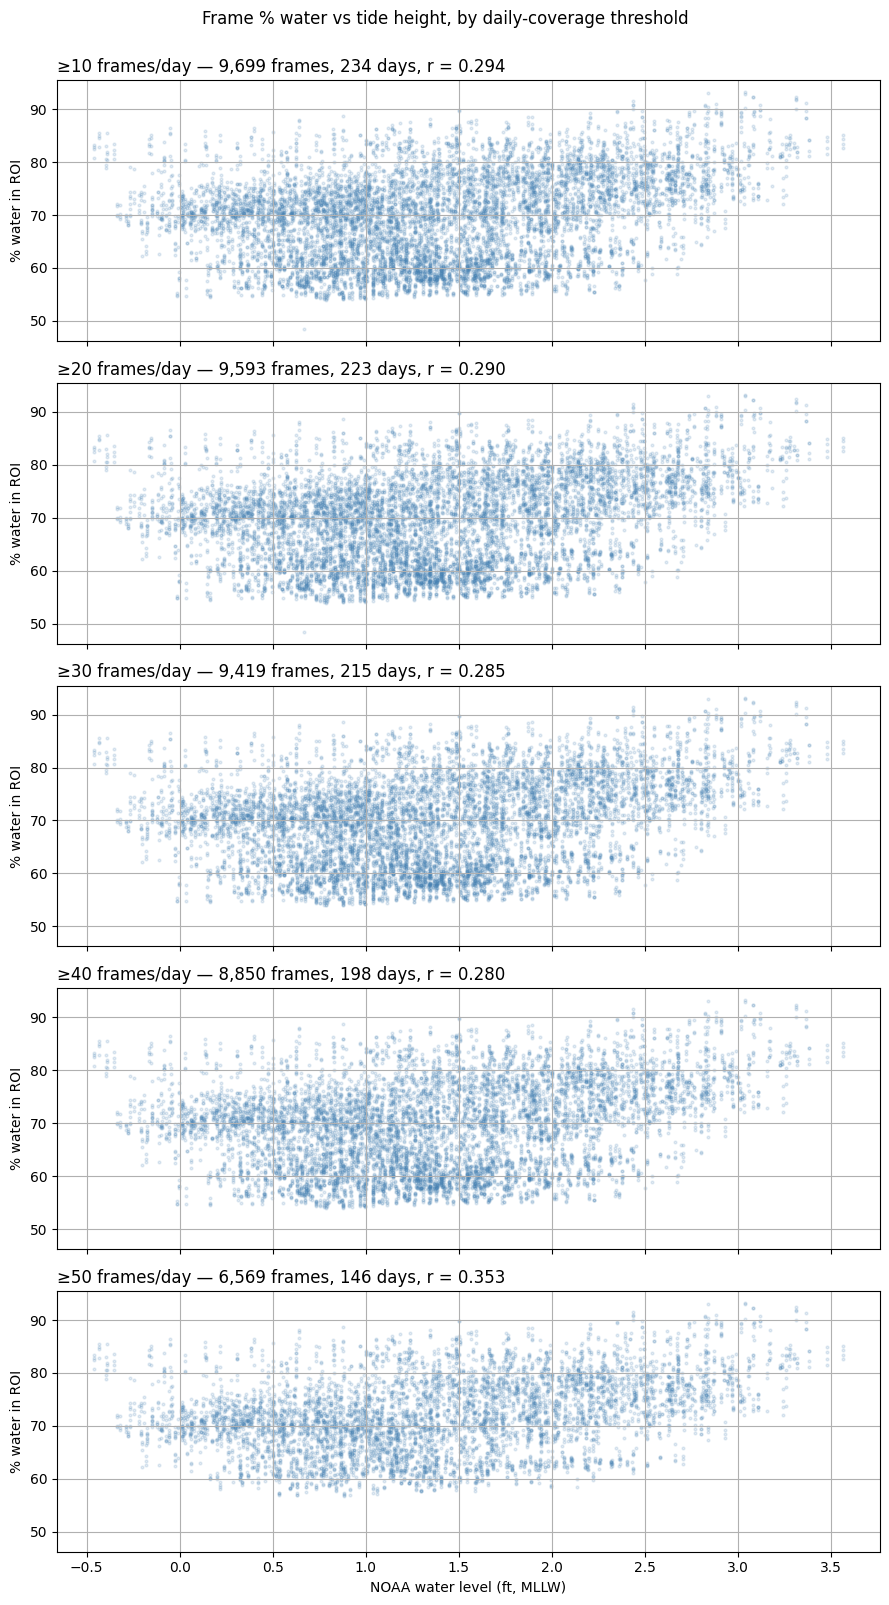

In [8]:
# Frame % water vs tide height — at increasing daily-coverage thresholds.
# A frame only enters a panel if its day has >= min_frames clean frames.
fig, axes = plt.subplots(5, 1, figsize=(9, 16), sharex=True, sharey=True)
for ax, min_frames in zip(axes, [10, 20, 30, 40, 50]):
    good_days = daily_n[daily_n >= min_frames].index
    m = merged[merged['date'].isin(good_days)]
    ax.scatter(m['water_level_ft'], m['pct_water'], s=4, alpha=0.15,
               color='steelblue')
    r = m['water_level_ft'].corr(m['pct_water'])
    ax.set_title(f'≥{min_frames} frames/day — {len(m):,} frames, '
                 f'{len(good_days)} days, r = {r:.3f}', loc='left')
    ax.set_ylabel('% water in ROI')
axes[-1].set_xlabel('NOAA water level (ft, MLLW)')
fig.suptitle('Frame % water vs tide height, by daily-coverage threshold',
             y=1.0)
plt.tight_layout(); plt.show()

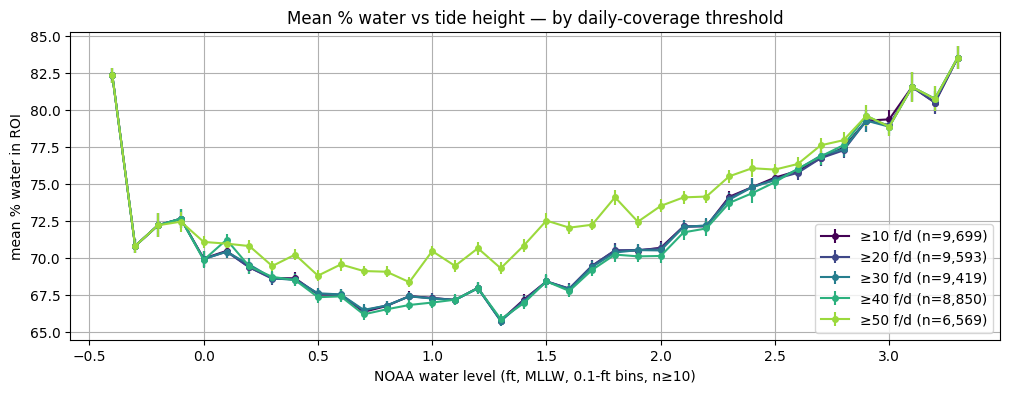

In [9]:
# binned response curves — one per daily-coverage threshold
merged['tide_bin'] = merged['water_level_ft'].round(1)
colors = plt.cm.viridis(np.linspace(0, 0.85, 5))
fig, ax = plt.subplots()
for (min_frames, c) in zip([10, 20, 30, 40, 50], colors):
    good_days = daily_n[daily_n >= min_frames].index
    m = merged[merged['date'].isin(good_days)]
    b = m.groupby('tide_bin')['pct_water'].agg(['mean', 'sem', 'count'])
    b = b[b['count'] >= 10]
    ax.errorbar(b.index, b['mean'], yerr=b['sem'], marker='o', ms=4,
                color=c, label=f'≥{min_frames} f/d (n={len(m):,})')
ax.set(xlabel='NOAA water level (ft, MLLW, 0.1-ft bins, n≥10)',
       ylabel='mean % water in ROI',
       title='Mean % water vs tide height — by daily-coverage threshold')
ax.legend(); plt.show()

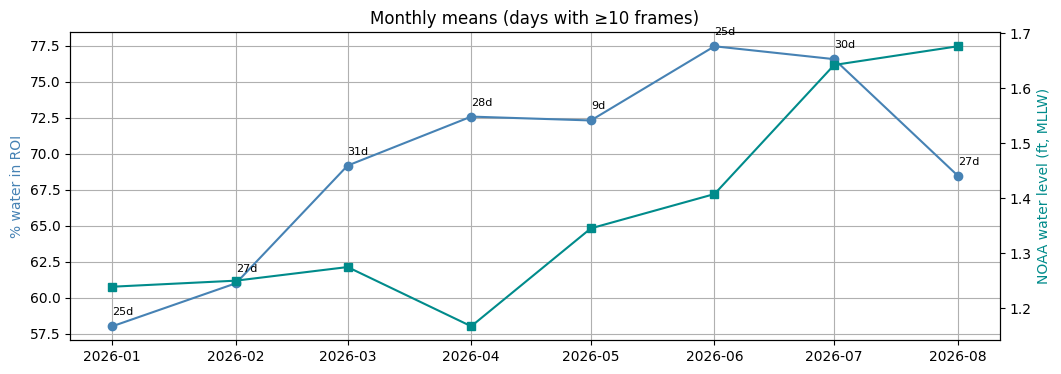

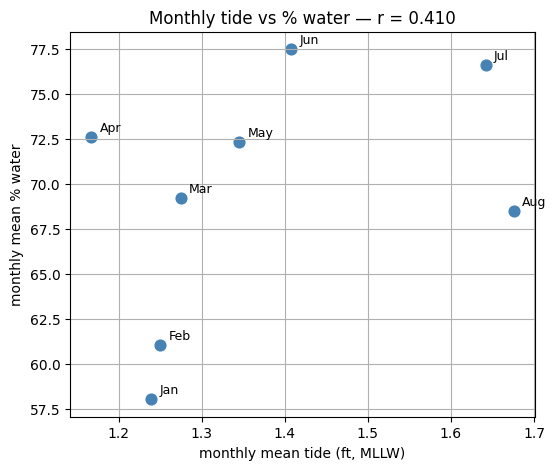

,tide,pct_water,pct_beach,n_days
date,,,,
2026-01-01,1.24,58.03,41.50,25
2026-02-01,1.25,61.02,38.64,27
2026-03-01,1.27,69.19,30.50,31
2026-04-01,1.17,72.59,27.10,28
2026-05-01,1.34,72.32,27.34,9
2026-06-01,1.41,77.47,22.23,25
2026-07-01,1.64,76.58,23.12,30
2026-08-01,1.68,68.49,31.12,27


In [10]:
# Monthly scale: mean tide height vs mean % water.
# Aggregate per day first (equal weight per day — a 50-frame day counts the
# same as a 10-frame day), then per month. Only days with >=10 frames count.
MIN_F = 10
good = daily_n[daily_n >= MIN_F].index
md = (merged[merged['date'].isin(good)]
      .groupby('date')
      .agg(pct_water=('pct_water', 'mean'),
           pct_beach=('pct_beach', 'mean'),
           tide=('water_level_ft', 'mean')))
md.index = pd.to_datetime(md.index)
monthly = md.resample('MS').agg(
    tide=('tide', 'mean'), pct_water=('pct_water', 'mean'),
    pct_beach=('pct_beach', 'mean'), n_days=('tide', 'size'))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly['pct_water'], 'o-', color='steelblue',
        label='mean % water')
ax.set_ylabel('% water in ROI', color='steelblue')
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(monthly.index, monthly['tide'], 's-', color='darkcyan',
         label='mean tide (ft)')
ax2.set_ylabel('NOAA water level (ft, MLLW)', color='darkcyan')
ax.set_title(f'Monthly means (days with ≥{MIN_F} frames)')
for x, n in zip(monthly.index, monthly['n_days']):
    ax.annotate(f'{int(n)}d', (x, monthly.loc[x, 'pct_water']),
                textcoords='offset points', xytext=(0, 8), fontsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(monthly['tide'], monthly['pct_water'], s=60, color='steelblue')
for x, row in monthly.iterrows():
    ax.annotate(x.strftime('%b'), (row['tide'], row['pct_water']),
                textcoords='offset points', xytext=(6, 4), fontsize=9)
r = monthly['tide'].corr(monthly['pct_water'])
ax.set(xlabel='monthly mean tide (ft, MLLW)', ylabel='monthly mean % water',
       title=f'Monthly tide vs % water — r = {r:.3f}')
plt.show()
monthly.round(2)

### Predicted tide — TPT2799 high/low predictions

`external_data/NOAA_water_level/CO-OPS__TPT2799__pr.csv` is the CO-OPS
**predicted high/low tide** series for subordinate station **TPT2799**
(columns: `Date Time`, `Prediction` ft, `Type` = H/L). It covers the whole
capture window (Jan 1 – Oct 8, 2026) — better coverage than the hourly
Kahului observations, which end Aug 31. To compare against frame stats, the
H/L extrema are linearly interpolated onto each frame's timestamp (crude —
real tide isn't linear between extrema — but adequate for ±0.2 ft).

TPT2799 range: 2026-01-01 03:05:00 -> 2026-10-08 20:26:00 | 998 H/L events
11,283 frames with predicted tide (100% of day frames)


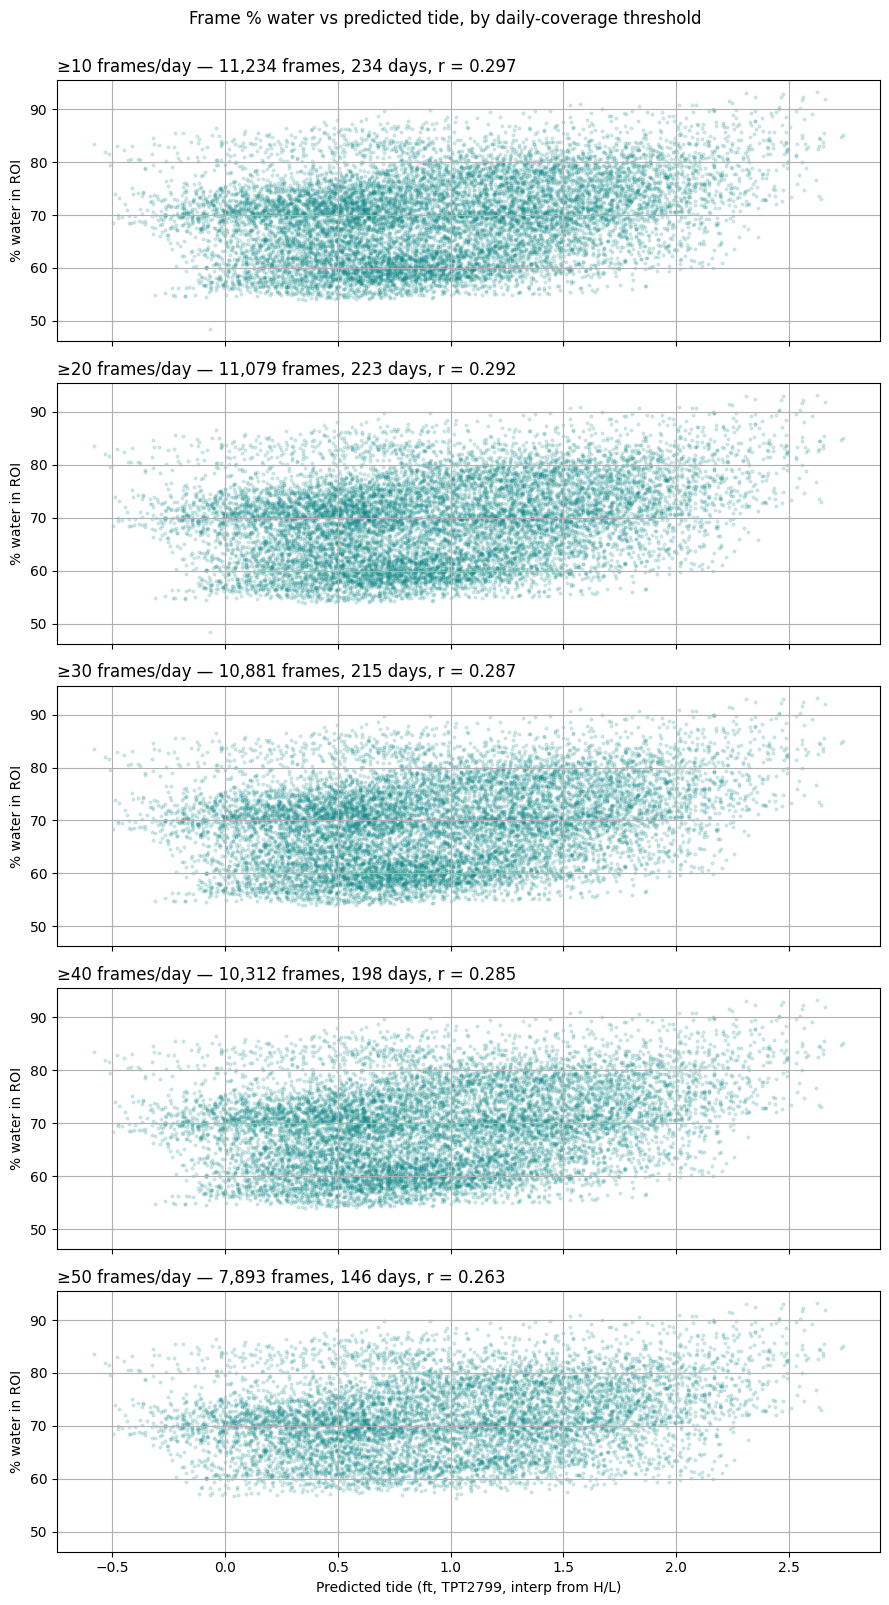

In [11]:
# interpolate predicted H/L extrema onto frame timestamps
tpt = pd.read_csv('external_data/NOAA_water_level/CO-OPS__TPT2799__pr.csv',
                  skipinitialspace=True)
tpt.columns = [c.strip() for c in tpt.columns]
tpt['local_dt'] = pd.to_datetime(tpt['Date Time'])
tide_series = pd.Series(tpt['Prediction'].values,
                        index=tpt['local_dt']).sort_index()
print('TPT2799 range:', tpt['local_dt'].min(), '->',
      tpt['local_dt'].max(), f"| {len(tpt):,} H/L events")

ftimes = day['local_dt']
interp = (tide_series.reindex(tide_series.index.union(ftimes))
          .interpolate('time').reindex(ftimes))
merged_pr = day.assign(tide_pred=interp.values)
merged_pr = merged_pr.dropna(subset=['tide_pred'])
print(f'{len(merged_pr):,} frames with predicted tide '
      f'({len(merged_pr)/len(day):.0%} of day frames)')

# same 5-threshold view as the observed-tide scatter
fig, axes = plt.subplots(5, 1, figsize=(9, 16), sharex=True, sharey=True)
for ax, min_frames in zip(axes, [10, 20, 30, 40, 50]):
    good_days = daily_n[daily_n >= min_frames].index
    m = merged_pr[merged_pr['date'].isin(good_days)]
    ax.scatter(m['tide_pred'], m['pct_water'], s=4, alpha=0.15,
               color='teal')
    r = m['tide_pred'].corr(m['pct_water'])
    ax.set_title(f'≥{min_frames} frames/day — {len(m):,} frames, '
                 f'{len(good_days)} days, r = {r:.3f}', loc='left')
    ax.set_ylabel('% water in ROI')
axes[-1].set_xlabel('Predicted tide (ft, TPT2799, interp from H/L)')
fig.suptitle('Frame % water vs predicted tide, by daily-coverage threshold',
             y=1.0)
plt.tight_layout(); plt.show()

### Waterline y-position vs tide

`extract_waterline.py` reads each saved mask, takes the **largest connected
water component**, and records its deepest row per column (columns need ≥20
water px to vote). `wl_y_median` = median of that lower boundary across
columns — a sharper tide proxy than `% water` area, since it's a length scale
rather than an area.

- Larger `wl_y` = waterline further down the image = **higher** water on the
  beach → expect *positive* correlation with tide height.
- Frozen-duplicate frames are excluded automatically: masks for dropped
  frames simply aren't in the cleaned `day` dataframe.
- Still an image-space metric: the camera-move epoch (Jan 27) shifts pixel
  geometry, so treat pre/post eras separately (as with the area stats).

11,516 masks with waterline stats | wl_y_median range 705-853 px
11,283 frames w/ predicted tide | 9,740 w/ observed tide


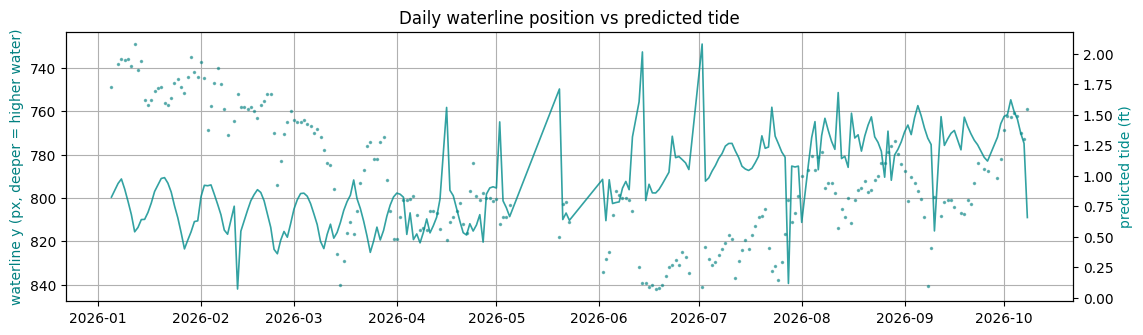

In [12]:
wl = pd.read_csv('Kaanapali_full_segformer_v2/waterline_stats.csv')
print(f'{len(wl):,} masks with waterline stats | '
      f'wl_y_median range {wl.wl_y_median.min():.0f}-'
      f'{wl.wl_y_median.max():.0f} px')

# join waterline to both tide sources (day is already deduped)
wl_pr = merged_pr.merge(wl, on='image')          # predicted tide (TPT2799)
wl_obs = merged.merge(wl, on='image')            # observed tide (Kahului)
print(f'{len(wl_pr):,} frames w/ predicted tide | '
      f'{len(wl_obs):,} w/ observed tide')

# sanity: daily waterline depth vs predicted tide over the capture window
wl_daily = wl_pr.groupby('date').agg(
    wl_y=('wl_y_median', 'median'),
    tide=('tide_pred', 'mean'), n=('image', 'size'))
wl_daily.index = pd.to_datetime(wl_daily.index)
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(wl_daily.index, wl_daily['wl_y'], '.', ms=3, color='teal',
        alpha=0.5, label='daily median waterline y')
ax.set_ylabel('waterline y (px, deeper = higher water)', color='teal')
ax.invert_yaxis()
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(wl_daily.index, wl_daily['tide'], '-', color='darkcyan',
         lw=1.2, alpha=0.8, label='mean predicted tide')
ax2.set_ylabel('predicted tide (ft)', color='darkcyan')
ax.set_title('Daily waterline position vs predicted tide')
plt.show()

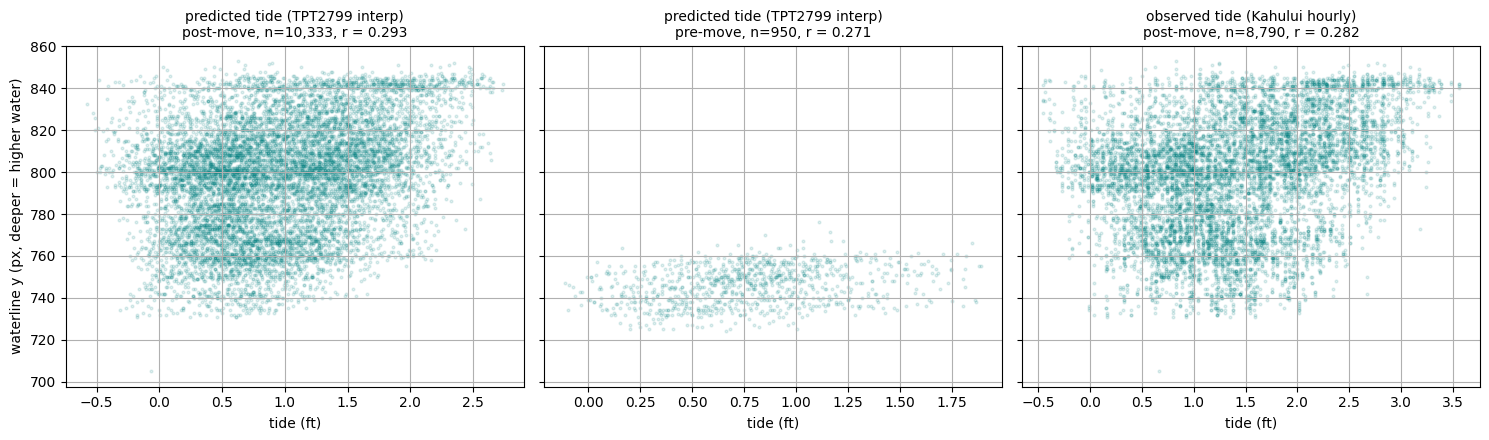

In [13]:
# waterline y vs tide — frame level, split by camera epoch
# (pixel geometry changed at the Jan 27 move, so pools can't be mixed)
CUTOFF = pd.Timestamp('2026-01-27')
panels = [
    ('predicted tide (TPT2799 interp)', 'tide_pred', wl_pr, 'post'),
    ('predicted tide (TPT2799 interp)', 'tide_pred', wl_pr, 'pre'),
    ('observed tide (Kahului hourly)', 'water_level_ft', wl_obs, 'post'),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (src, col, df, ep) in zip(axes, panels):
    if ep == 'post':
        m = df[df['local_dt'] >= CUTOFF]
    else:
        m = df[df['local_dt'] < CUTOFF]
    ax.scatter(m[col], m['wl_y_median'], s=4, alpha=0.12, color='teal')
    r = m[col].corr(m['wl_y_median'])
    ax.set_title(f'{src}\n{ep}-move, n={len(m):,}, r = {r:.3f}',
                 fontsize=10)
    ax.set_xlabel('tide (ft)')
axes[0].set_ylabel('waterline y (px, deeper = higher water)')
plt.tight_layout(); plt.show()

In [14]:
# does the tide relationship differ pre/post camera move? (ROI changed)
CUTOFF = pd.Timestamp('2026-01-27')
merged['epoch'] = np.where(merged['local_dt'] < CUTOFF, 'pre-move', 'post-move')
for ep, g in merged.groupby('epoch'):
    print(ep, f"n={len(g):,}",
          f"r(water~tide)={g['water_level_ft'].corr(g['pct_water']):.3f}",
          f"| mean pct_beach {g['pct_beach'].mean():.1f}% vs "
          f"{g['pct_water'].mean():.1f}% water")

post-move n=8,790 r(water~tide)=0.314 | mean pct_beach 28.9% vs 70.8% water
pre-move n=950 r(water~tide)=0.192 | mean pct_beach 41.3% vs 58.2% water


## Next steps

- ~~Extract the actual **waterline y-position**~~ → done (`extract_waterline.py`
  → `waterline_stats.csv`, joined above). Next refinement: convert pixel y to
  cross-shore distance via a rough homography, or at least verify stability
  with per-column IQR.
- Add swell/rain covariates — wave run-up moves % water independently of tide.
- People counts → carrying-capacity analysis.
- Check residual autocorrelation before any significance claims
  (15-min frames are far from independent).